## 1. Application of the Logistic Regression Model

In [11]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

data = pd.read_csv('bioresponse.csv')

In [12]:
X = data.drop('Activity', axis=1)
Y = data['Activity']

X_train_raw, X_test_raw, Y_train_raw, Y_test_raw = train_test_split(
    X, Y, test_size=0.25, random_state=42, stratify=Y
)

x_train = X_train_raw.values.T
y_train = Y_train_raw.values.reshape(1, -1)
x_test = X_test_raw.values.T
y_test = Y_test_raw.values.reshape(1, -1)

In [13]:
def sigmoid(z):
    return 1. / (1. + np.exp(-z))

def initialize_with_zeros(dim):
    w = np.random.normal(loc=0.0, scale=1.0, size=dim).reshape(dim, 1)
    b = 0.
    return w, b

def propagate(w, b, X, Y):
    m = X.shape[1]
    A = sigmoid(np.dot(w.T, X) + b)
    epsilon = 1e-15
    A = np.clip(A, epsilon, 1 - epsilon)
    cost = -(1. / m) * np.sum(Y * np.log(A) + (1 - Y) * np.log(1 - A), axis=1)
    dw = (1. / m) * np.dot(X, (A - Y).T)
    db = (1. / m) * np.sum(A - Y, axis=1)
    grads = {"dw": dw, "db": db}
    return grads, cost

def predict(w, b, X, threshold=0.5):
    m = X.shape[1]
    Y_prediction = np.zeros((1, m))
    w = w.reshape(X.shape[0], 1)
    A = sigmoid(np.dot(w.T, X) + b)
    Y_prediction = (A > threshold).astype(float)
    return Y_prediction

## 2. Modification of optimize()

In [14]:
def optimize(w, b, X, Y, num_iterations, learning_rate, print_cost=False):
    costs = []
    for i in range(num_iterations):
        grads, cost = propagate(w, b, X, Y)
        dw = grads["dw"]
        db = grads["db"]
        w -= learning_rate * dw
        b -= learning_rate * db
        if i % 100 == 0:
            costs.append(cost)
        if print_cost and i % 500 == 0:
            print(f"GD Cost after iteration {i}: {cost[0]:.7f}")
    params = {"w": w, "b": b}
    return params, grads, costs

def optimize_sgd(w, b, X, Y, num_iterations, learning_rate, print_cost=False):
    costs = []
    m = X.shape[1]
    for i in range(num_iterations):
        idx = np.random.randint(0, m) 
        xi = X[:, idx:idx+1]
        yi = Y[:, idx:idx+1]
        grads, cost = propagate(w, b, xi, yi)
        dw = grads["dw"]
        db = grads["db"]
        w -= learning_rate * dw
        b -= learning_rate * db
        if i % 100 == 0:
            costs.append(cost)
        if print_cost and i % 1000 == 0:
            print(f"SGD Cost after iteration {i}: {cost[0]:.7f}")
    params = {"w": w, "b": b}
    return params, grads, costs

## 3. Adam optimization

In [15]:
def optimize_adam(w, b, X, Y, num_iterations, learning_rate=0.01, beta1=0.9, beta2=0.999, epsilon=1e-8):
    costs = []
    m, n = X.shape[1], X.shape[0]
    v_w, s_w = np.zeros_like(w), np.zeros_like(w)
    v_b, s_b = 0.0, 0.0
    for t in range(1, num_iterations + 1):
        grads, cost = propagate(w, b, X, Y)
        dw, db = grads["dw"], grads["db"]
        
        v_w = beta1 * v_w + (1 - beta1) * dw
        v_b = beta1 * v_b + (1 - beta1) * db
        s_w = beta2 * s_w + (1 - beta2) * dw**2
        s_b = beta2 * s_b + (1 - beta2) * db**2
        
        v_w_corr = v_w / (1 - beta1**t)
        v_b_corr = v_b / (1 - beta1**t)
        s_w_corr = s_w / (1 - beta2**t)
        s_b_corr = s_b / (1 - beta2**t)
        
        w -= learning_rate * v_w_corr / (np.sqrt(s_w_corr) + epsilon)
        b -= learning_rate * v_b_corr / (np.sqrt(s_b_corr) + epsilon)
        if t % 100 == 0:
            costs.append(cost)
    params = {"w": w, "b": b}
    return params, costs

## 4. Plot of learning curves

In [17]:
def get_accuracy(w, b, X, Y):
    pred = predict(w, b, X)
    return 100 - np.mean(np.abs(pred - Y) * 100)

# Пункт 1: Classic GD
print("\n--- Classic GD ---")
w_gd, b_gd = initialize_with_zeros(x_train.shape[0])
params_gd, grads_gd, costs_gd = optimize(w_gd, b_gd, x_train, y_train, 2000, 0.5, True)
acc_gd_train = get_accuracy(params_gd["w"], params_gd["b"], x_train, y_train)
acc_gd_test = get_accuracy(params_gd["w"], params_gd["b"], x_test, y_test)
print(f"GD Train Acc: {acc_gd_train:.2f}%, Test Acc: {acc_gd_test:.2f}%")

# Пункт 2: SGD
print("\n--- SGD ---")
w_sgd, b_sgd = initialize_with_zeros(x_train.shape[0])
params_sgd, costs_sgd, costs_sgd = optimize_sgd(w_sgd, b_sgd, x_train, y_train, 2000, 0.5, True)
acc_sgd_train = get_accuracy(params_sgd["w"], params_sgd["b"], x_train, y_train)
acc_sgd_test = get_accuracy(params_sgd["w"], params_sgd["b"], x_test, y_test)
print(f"SGD Train Acc: {acc_sgd_train:.2f}%, Test Acc: {acc_sgd_test:.2f}%")

# Пункт 3: Adam
print("\n--- Adam ---")
w_adam, b_adam = initialize_with_zeros(x_train.shape[0])
params_adam, costs_adam = optimize_adam(w_adam, b_adam, x_train, y_train, 2000, learning_rate=0.01)
acc_adam_train = get_accuracy(params_adam["w"], params_adam["b"], x_train, y_train)
acc_adam_test = get_accuracy(params_adam["w"], params_adam["b"], x_test, y_test)
print(f"Adam Train Acc: {acc_adam_train:.2f}%, Test Acc: {acc_adam_test:.2f}%")


--- Classic GD ---
GD Cost after iteration 0: 3.9557152
GD Cost after iteration 500: 0.7727401
GD Cost after iteration 1000: 0.6413028
GD Cost after iteration 1500: 0.5742085
GD Train Acc: 81.19%, Test Acc: 71.75%

--- SGD ---
SGD Cost after iteration 0: 12.2342221
SGD Cost after iteration 1000: 11.1690814
SGD Train Acc: 67.29%, Test Acc: 65.14%

--- Adam ---
Adam Train Acc: 95.13%, Test Acc: 73.13%


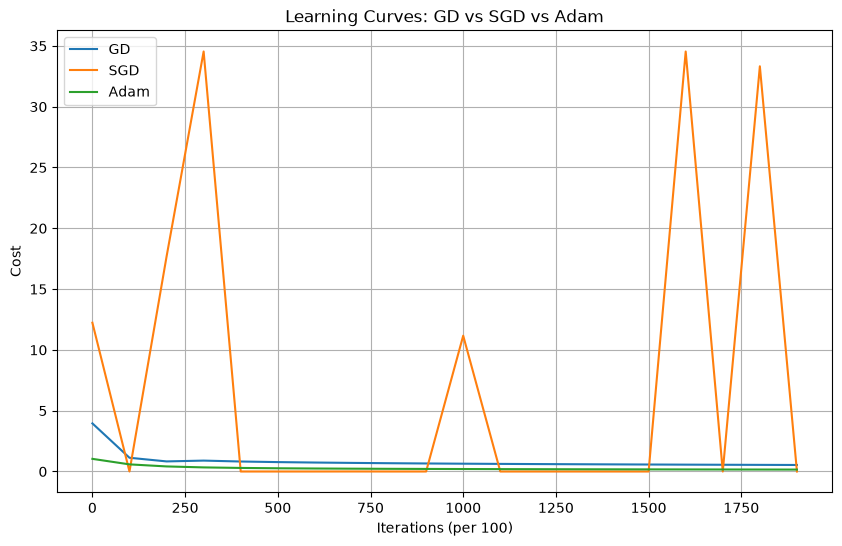

In [18]:
plt.figure(figsize=(10, 6))
plt.plot(np.arange(len(costs_gd)) * 100, costs_gd, label='GD')
plt.plot(np.arange(len(costs_sgd)) * 100, costs_sgd, label='SGD')
plt.plot(np.arange(len(costs_adam)) * 100, costs_adam, label='Adam')
plt.xlabel('Iterations (per 100)')
plt.ylabel('Cost')
plt.title('Learning Curves: GD vs SGD vs Adam')
plt.legend()
plt.grid(True)
plt.show()

## 5. The Impact of Learning Rate

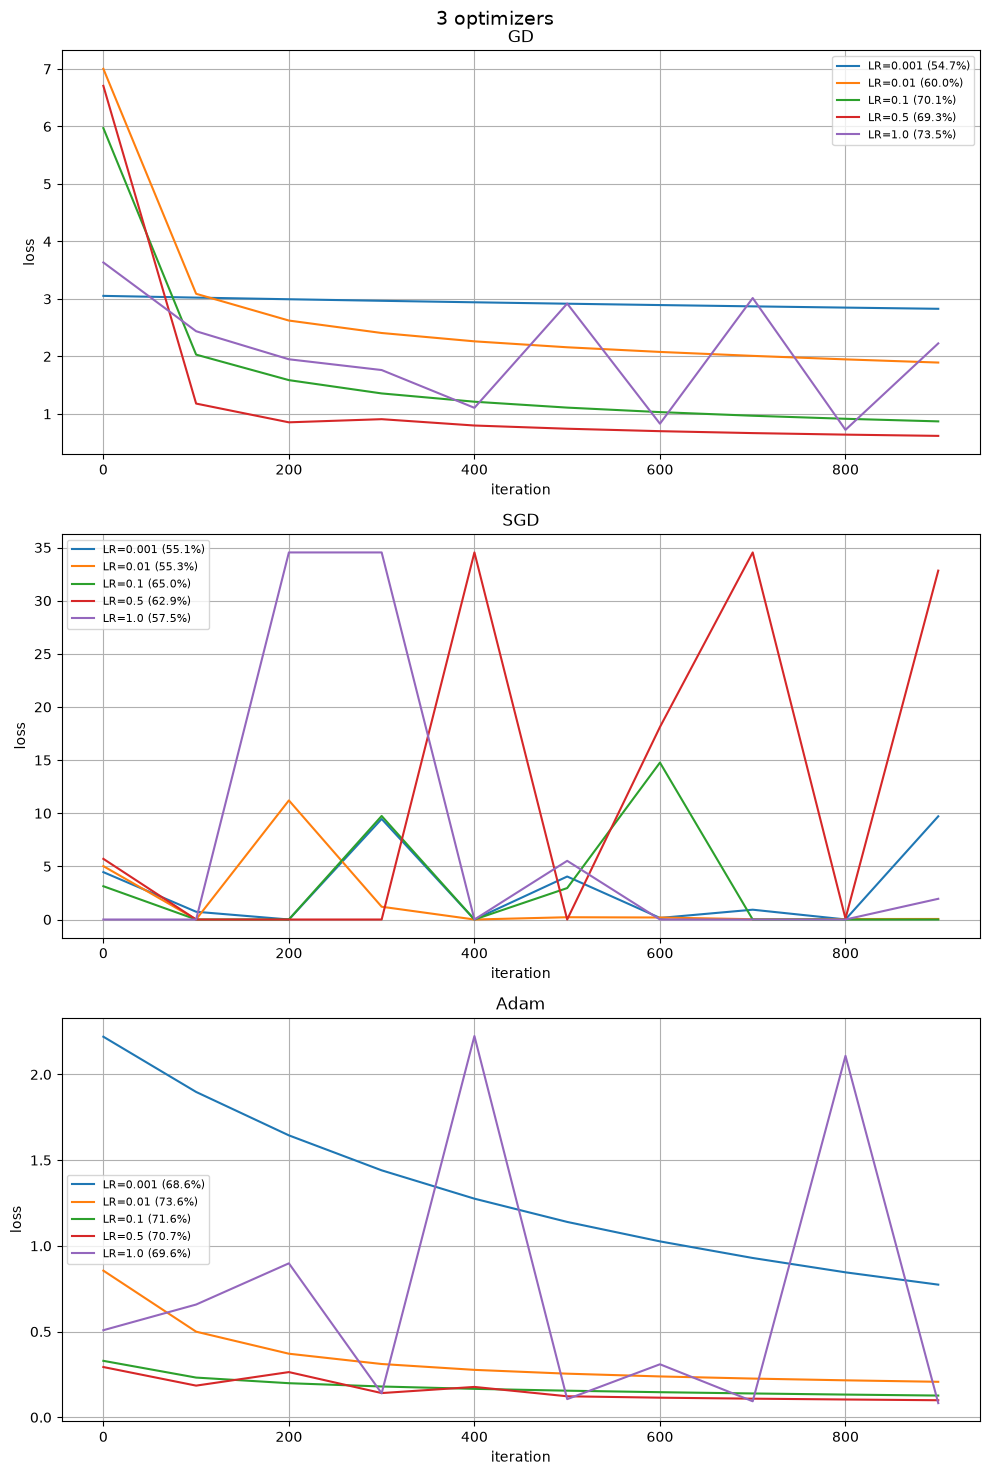

In [21]:
import warnings

learning_rates = [0.001, 0.01, 0.1, 0.5, 1.0]

fig, axes = plt.subplots(3, 1, figsize=(10, 15))

for ax, (name, opt_func) in zip(axes, [('GD', 'gd'), ('SGD', 'sgd'), ('Adam', 'adam')]):
    for lr in learning_rates:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            w_lr, b_lr = initialize_with_zeros(x_train.shape[0])

            if opt_func == 'gd':
                params_lr, grads_lr, costs_lr = optimize(
                    w_lr, b_lr, x_train, y_train, 1000, lr
                )
            elif opt_func == 'sgd':
                params_lr, grads_lr, costs_lr = optimize_sgd(
                    w_lr, b_lr, x_train, y_train, 1000, lr
                )
            else:
                params_lr, costs_lr = optimize_adam(
                    w_lr, b_lr, x_train, y_train, 1000, learning_rate=lr
                )

        acc_test = get_accuracy(params_lr["w"], params_lr["b"], x_test, y_test)
        ax.plot(np.arange(len(costs_lr)) * 100, costs_lr, label=f'LR={lr} ({acc_test:.1f}%)')

    ax.set_title(name)
    ax.set_xlabel('iteration')
    ax.set_ylabel('loss')
    ax.legend(fontsize=8)
    ax.grid(True)

plt.suptitle('3 optimizers', fontsize=14)
plt.tight_layout()
plt.show()